# Penguins on-ice expected goals: for, against, and a combined score

This notebook uses MoneyPuck's official Pittsburgh skater summary for the 2025-26 regular season. It explains the source, shows the raw file, turns the expected-goal columns into fairer per-60-minute rates, checks the calculations, and creates one chart and a clean CSV. Read each plain-English note before running the code cell below it.

## What these numbers mean

- **xGoals For (xGF):** expected goals by Pittsburgh while this player was on the ice.
- **xGoals Against (xGA):** expected goals by opponents while this player was on the ice.
- **xGoals Difference (xGD):** xGF minus xGA. Above zero is a positive chance balance; below zero is a negative balance.

These are team results during the player's shifts, not just events the player personally created. MoneyPuck defines on-ice stats as including all events while the player is on the ice. [MoneyPuck glossary](https://www.moneypuck.com/glossary.htm).

## 1. Read the official source file

MoneyPuck publishes team skater CSV files. This one is the Pittsburgh (`PIT`) file under the 2025 season folder, which represents the 2025-26 season. A CSV is a plain table saved as text. We use the copy saved in `data/`, so the analysis works offline; the source address is included here for reference.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / 'data').exists():
    PROJECT_DIR = PROJECT_DIR.parent
DATA_FILE = PROJECT_DIR / 'data' / 'moneypuck_pit_2025_26_skaters_latest.csv'
SOURCE_URL = 'https://moneypuck.com/moneypuck/playerData/seasonSummary/2025/regular/teams/skaters/PIT.csv'
raw = pd.read_csv(DATA_FILE)
print('MoneyPuck source:', SOURCE_URL)
print(f'File contains {len(raw)} rows and {len(raw.columns)} columns.')

MoneyPuck source: https://moneypuck.com/moneypuck/playerData/seasonSummary/2025/regular/teams/skaters/PIT.csv
File contains 190 rows and 154 columns.


## 2. Inspect the raw rows

A player appears in several rows because MoneyPuck separates ice situations such as all situations, 5-on-5, and power play. Each row also has many columns. We will look at a few relevant columns before choosing the `all` row, which combines a player's situations without counting that player several times. The `OnIce_F_xGoals` and `OnIce_A_xGoals` columns contain the for and against totals we need.

In [2]:
print('Situations in the file:', ', '.join(sorted(raw['situation'].unique())))
print('xGoals fields:', [column for column in raw.columns if 'xGoals' in column and ('OnIce_F_' in column or 'OnIce_A_' in column)][:8])
raw[['name', 'situation', 'games_played', 'icetime', 'OnIce_F_xGoals', 'OnIce_A_xGoals']].head(8)

Situations in the file: 4on5, 5on4, 5on5, all, other
xGoals fields: ['OnIce_F_xGoals', 'OnIce_F_flurryAdjustedxGoals', 'OnIce_F_scoreVenueAdjustedxGoals', 'OnIce_F_flurryScoreVenueAdjustedxGoals', 'OnIce_F_lowDangerxGoals', 'OnIce_F_mediumDangerxGoals', 'OnIce_F_highDangerxGoals', 'OnIce_F_xGoalsFromxReboundsOfShots']


,name,situation,games_played,icetime,OnIce_F_xGoals,OnIce_A_xGoals
0,Kevin Hayes,other,28,287.0,0.08,1.51
1,Kevin Hayes,all,28,20956.0,16.22,13.66
2,Kevin Hayes,5on5,28,18841.0,13.98,11.22
3,Kevin Hayes,4on5,28,2.0,0.00,0.00
4,Kevin Hayes,5on4,28,1826.0,2.15,0.84
5,Sam Poulin,other,2,0.0,0.00,0.00
6,Sam Poulin,all,2,1658.0,0.81,0.80
7,Sam Poulin,5on5,2,1589.0,0.81,0.76


## 3. Build the player comparison

Season totals are useful, but players who play more minutes naturally have more chances for their totals to grow. So we also divide each total by ice time and scale it to 60 minutes. We keep players with at least 10 games **and** 300 minutes to reduce the influence of very small samples.

For one combined score, we first compare each player with this eligible Penguins group. We calculate how far above-average their xGF per 60 is, and how far below-average their xGA per 60 is. We express each comparison in standard-deviation units, then average the two equally. A positive score means a better-than-group-average blend of creating and limiting expected goals; a negative score means worse. We show xGD too, but do not add it into the score because xGD is already xGF minus xGA.

In [3]:
players = raw.loc[raw['situation'].eq('all')].copy()
players['Player'] = players['name'].str.strip()
players['Minutes'] = pd.to_numeric(players['icetime']) / 60
players['xGF'] = pd.to_numeric(players['OnIce_F_xGoals'])
players['xGA'] = pd.to_numeric(players['OnIce_A_xGoals'])
players['xG difference'] = players['xGF'] - players['xGA']
players['xGF per 60'] = players['xGF'] / players['Minutes'] * 60
players['xGA per 60'] = players['xGA'] / players['Minutes'] * 60
players['xG difference per 60'] = players['xGF per 60'] - players['xGA per 60']
eligible = players.loc[players['games_played'].ge(10) & players['Minutes'].ge(300)].copy()

for_z = (eligible['xGF per 60'] - eligible['xGF per 60'].mean()) / eligible['xGF per 60'].std(ddof=0)
prevention_z = (eligible['xGA per 60'].mean() - eligible['xGA per 60']) / eligible['xGA per 60'].std(ddof=0)
eligible['xGF strength (z)'] = for_z
eligible['xGA prevention (z)'] = prevention_z
eligible['Combined impact score'] = (for_z + prevention_z) / 2
eligible['Rank'] = eligible['Combined impact score'].rank(method='min', ascending=False).astype(int)

result = eligible[['Rank', 'Player', 'position', 'games_played', 'Minutes', 'xGF', 'xGA',
                   'xG difference', 'xGF per 60', 'xGA per 60', 'xG difference per 60',
                   'Combined impact score']].copy()
result = result.rename(columns={'position': 'Position', 'games_played': 'Games'})
result = result.sort_values('Rank').reset_index(drop=True)
round_columns = ['Minutes', 'xGF', 'xGA', 'xG difference', 'xGF per 60', 'xGA per 60', 'xG difference per 60', 'Combined impact score']
result[round_columns] = result[round_columns].round(2)
result.to_csv(PROJECT_DIR / 'data' / 'penguins_xgoal_compound_2025_26.csv', index=False)
print(f'Eligible players: {len(result)} of {len(players)} all-situations players. Clean table saved to data/penguins_xgoal_compound_2025_26.csv')
result

Eligible players: 24 of 38 all-situations players. Clean table saved to data/penguins_xgoal_compound_2025_26.csv


,Rank,Player,Position,Games,Minutes,xGF,xGA,xG difference,xGF per 60,xGA per 60,xG difference per 60,Combined impact score
0,1,Evgeni Malkin,C,56,985.25,76.70,49.12,27.58,4.67,2.99,1.68,1.06
1,2,Ilya Solovyov,D,30,382.40,19.66,14.31,5.35,3.08,2.25,0.84,0.74
2,3,Ville Koivunen,R,39,496.77,24.59,18.38,6.21,2.97,2.22,0.75,0.68
3,4,Tommy Novak,C,82,1171.07,65.70,50.35,15.35,3.37,2.58,0.79,0.56
4,5,Sidney Crosby,C,68,1307.70,91.06,67.95,23.11,4.18,3.12,1.06,0.54
5,6,Ben Kindel,C,77,1159.87,68.48,53.50,14.98,3.54,2.77,0.77,0.47
6,7,Anthony Mantha,R,81,1230.17,77.47,60.34,17.13,3.78,2.94,0.84,0.44
7,8,Kevin Hayes,R,28,349.27,16.22,13.66,2.56,2.79,2.35,0.44,0.39
8,9,Samuel Girard,D,60,1086.02,50.87,44.74,6.13,2.81,2.47,0.34,0.26
9,10,Erik Karlsson,D,75,1770.03,114.96,93.81,21.15,3.90,3.18,0.72,0.25


## 4. Check the calculations

These checks make sure we selected one row per player, applied the minutes and games cutoffs, kept xGoals non-negative, and calculated the difference correctly. The combined score is relative to the 24 eligible Penguins in this season; it is not a universal league rating.

In [4]:
checks = {
    'One row per eligible player': bool(result['Player'].is_unique),
    'All players meet both cutoffs': bool(eligible['games_played'].ge(10).all() and eligible['Minutes'].ge(300).all()),
    'Expected-goal totals are non-negative': bool((eligible['xGF'].ge(0) & eligible['xGA'].ge(0)).all()),
    'Difference equals xGF minus xGA': bool((eligible['xG difference'].sub(eligible['xGF'] - eligible['xGA']).abs() < 1e-9).all()),
    'Per-60 difference equals xGF/60 minus xGA/60': bool((eligible['xG difference per 60'].sub(eligible['xGF per 60'] - eligible['xGA per 60']).abs() < 1e-9).all()),
    'Combined score averages to zero in this group': abs(eligible['Combined impact score'].mean()) < 1e-9,
}
for description, passed in checks.items():
    print(f'{description}: {passed}')
assert all(checks.values()), 'Please inspect the data before relying on the ranking.'

One row per eligible player: True
All players meet both cutoffs: True
Expected-goal totals are non-negative: True
Difference equals xGF minus xGA: True
Per-60 difference equals xGF/60 minus xGA/60: True
Combined score averages to zero in this group: True


## 5. See the combined score

The bars are the combined score from the two rates, not raw xGoals totals. The vertical zero line means average among this eligible Penguins group. Gold bars are above that group average; gray bars are below it. The table above gives the actual xGF, xGA, and difference behind the score.

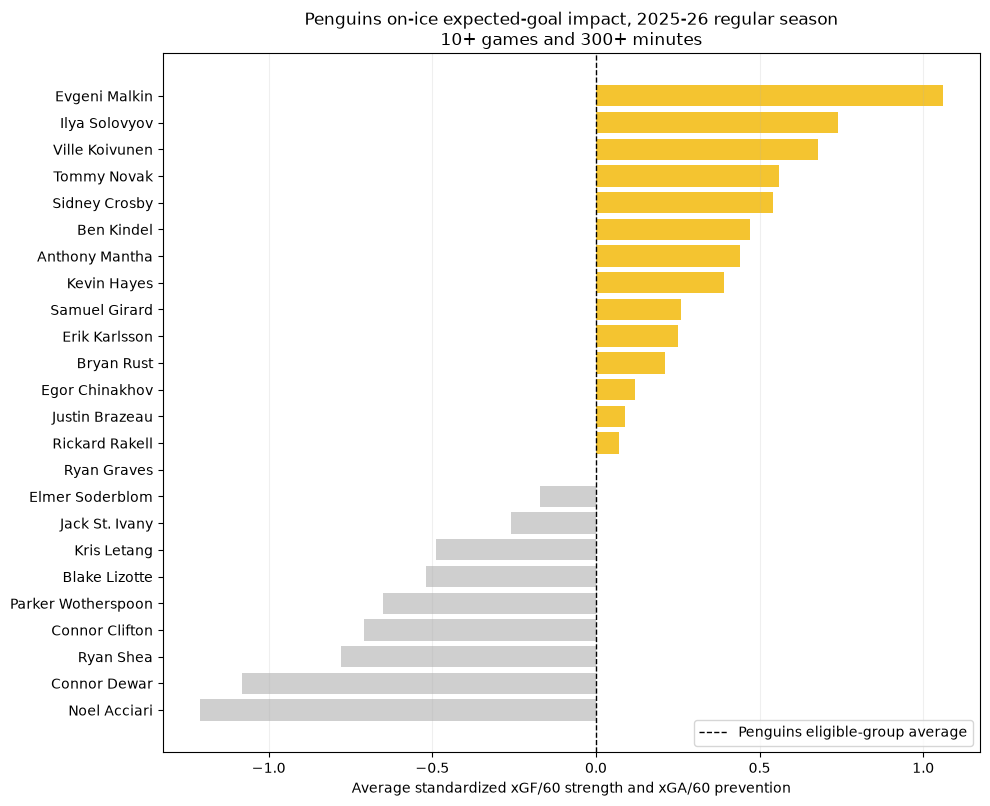

In [5]:
chart = result.sort_values('Combined impact score', ascending=True)
bar_colors = ['#cfcfcf' if score < 0 else '#f4c430' for score in chart['Combined impact score']]
fig, ax = plt.subplots(figsize=(10, max(7, len(chart) * 0.34)))
ax.barh(chart['Player'], chart['Combined impact score'], color=bar_colors)
ax.axvline(0, color='black', linewidth=1, linestyle='--', label='Penguins eligible-group average')
ax.set_xlabel('Average standardized xGF/60 strength and xGA/60 prevention')
ax.set_title('Penguins on-ice expected-goal impact, 2025-26 regular season\n10+ games and 300+ minutes')
ax.legend(loc='lower right')
ax.grid(axis='x', alpha=0.2)
plt.tight_layout()
fig.savefig(PROJECT_DIR / 'data' / 'penguins_xgoal_compound_2025_26.png', dpi=160, bbox_inches='tight')
plt.show()

## 6. What the results say

Malkin leads the combined score at about +1.06. Solovyov (+0.74) and Koivunen (+0.68) are next in this eligible group. This is consistent with their strong on-ice chance balance, but their minutes (about 382 and 497) are lower than many regulars, so their rates are less settled. The xG difference totals also show accumulated volume: a player's total can be smaller simply because they played fewer minutes.

The score describes team expected-goal results while a player was on the ice. It cannot separate the player from linemates, opponents, or role, and it does not prove cause and effect. For personal shot production, look separately at the player's own `I_F_xGoals` field.